### END TO END NLP PROJECT

#### Sprint 1 — Exploratory Data Analysis and Text Preprocessing

##### Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

In [2]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud

In [3]:
%pip install pandas numpy matplotlib seaborn nltk scikit-learn wordcloud

Note: you may need to restart the kernel to use updated packages.


##### Load Dataset

In [4]:
df = pd.read_csv(r"D:\MACHINE LEARNING\archive (4)\Reviews.csv")

In [5]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [6]:
df.shape

(568454, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [8]:
df.columns

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')

In [9]:
df.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time
count,568454.000000,568454.000000,568454.00000,568454.000000,5.684540e+05
mean,284227.500000,1.743817,2.22881,4.183199,1.296257e+09
std,164098.679298,7.636513,8.28974,1.310436,4.804331e+07
min,1.000000,0.000000,0.00000,1.000000,9.393408e+08
25%,142114.250000,0.000000,0.00000,4.000000,1.271290e+09
50%,284227.500000,0.000000,1.00000,5.000000,1.311120e+09
75%,426340.750000,2.000000,2.00000,5.000000,1.332720e+09
max,568454.000000,866.000000,923.00000,5.000000,1.351210e+09


##### Data Cleaning

In [10]:
#Check Missing Values
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [11]:
#Remove Duplicate Records
df=df.drop_duplicates()
df

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
568449,568450,B001EO7N10,A28KG5XORO54AY,Lettie D. Carter,0,0,5,1299628800,Will not do without,Great for sesame chicken..this is a good if no...
568450,568451,B003S1WTCU,A3I8AFVPEE8KI5,R. Sawyer,0,0,2,1331251200,disappointed,I'm disappointed with the flavor. The chocolat...
568451,568452,B004I613EE,A121AA1GQV751Z,"pksd ""pk_007""",2,2,5,1329782400,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
568452,568453,B004I613EE,A3IBEVCTXKNOH,"Kathy A. Welch ""katwel""",1,1,5,1331596800,Favorite Training and reward treat,These are the BEST treats for training and rew...


In [12]:
#Handle Missing review text
df=df.dropna(subset=["Text"])
df

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
568449,568450,B001EO7N10,A28KG5XORO54AY,Lettie D. Carter,0,0,5,1299628800,Will not do without,Great for sesame chicken..this is a good if no...
568450,568451,B003S1WTCU,A3I8AFVPEE8KI5,R. Sawyer,0,0,2,1331251200,disappointed,I'm disappointed with the flavor. The chocolat...
568451,568452,B004I613EE,A121AA1GQV751Z,"pksd ""pk_007""",2,2,5,1329782400,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
568452,568453,B004I613EE,A3IBEVCTXKNOH,"Kathy A. Welch ""katwel""",1,1,5,1331596800,Favorite Training and reward treat,These are the BEST treats for training and rew...


In [13]:
df=df.dropna(subset=["Score"])
df

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
568449,568450,B001EO7N10,A28KG5XORO54AY,Lettie D. Carter,0,0,5,1299628800,Will not do without,Great for sesame chicken..this is a good if no...
568450,568451,B003S1WTCU,A3I8AFVPEE8KI5,R. Sawyer,0,0,2,1331251200,disappointed,I'm disappointed with the flavor. The chocolat...
568451,568452,B004I613EE,A121AA1GQV751Z,"pksd ""pk_007""",2,2,5,1329782400,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
568452,568453,B004I613EE,A3IBEVCTXKNOH,"Kathy A. Welch ""katwel""",1,1,5,1331596800,Favorite Training and reward treat,These are the BEST treats for training and rew...


In [14]:
#Convert the timestamp
df["Time"] = pd.to_datetime(
    df["Time"], unit="s", errors="coerce"
)

In [15]:
df["Time"]

0        2011-04-27
1        2012-09-07
2        2008-08-18
3        2011-06-13
4        2012-10-21
            ...    
568449   2011-03-09
568450   2012-03-09
568451   2012-02-21
568452   2012-03-13
568453   2012-05-31
Name: Time, Length: 568454, dtype: datetime64[ns]

In [16]:
#Check rating distribution
df["Score"].value_counts().sort_index()

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64

##### Text Preprocessing

In [17]:
import re
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [18]:
def preprocess_text(text):
    text = str(text).lower()
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)
    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    # Tokenization
    words = text.split()
    # Remove stopwords, keeping "not"
    words = [
        word for word in words
        if word not in stop_words or word == "not"
    ]
    # Stemming
    words = [stemmer.stem(word) for word in words]

    return " ".join(words)

In [26]:
df["Cleaned_Review"] = df["Text"].apply(
    preprocess_text
)

In [28]:
df[["Text", "Cleaned_Review"]].head()

,Text,Cleaned_Review
0,I have bought several of the Vitality canned d...,bought sever vital can dog food product found ...
1,Product arrived labeled as Jumbo Salted Peanut...,product arriv label jumbo salt peanutsth peanu...
2,This is a confection that has been around a fe...,confect around centuri light pillowi citru gel...
3,If you are looking for the secret ingredient i...,look secret ingredi robitussin believ found go...
4,Great taffy at a great price. There was a wid...,great taffi great price wide assort yummi taff...


##### Exploratory Data Analysis (EDA)

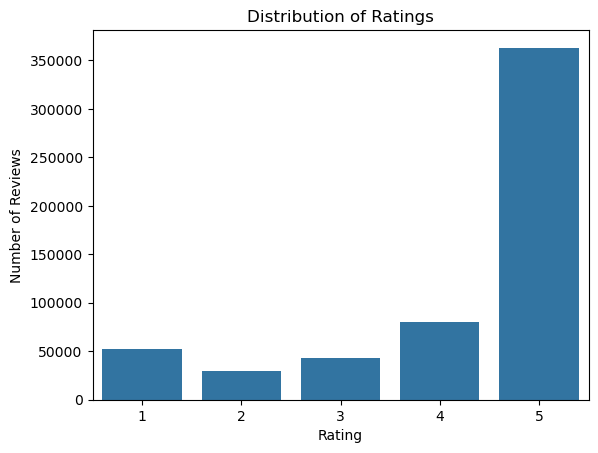

In [29]:
#Distribution of Ratings
sns.countplot(data=df, x="Score")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

Observations:

* The count plot shows the number of reviews for each rating (1 to 5) in the dataset.
    
* We can identify which rating is the most frequent and which rating is the least frequent by comparing the bar heights.
    
* The rating distribution helps us understand whether the dataset is balanced or dominated by certain ratings, which is important for sentiment analysis.

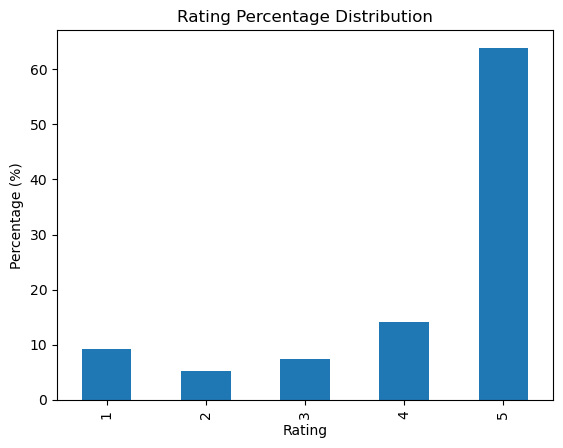

In [30]:
#Rating percentage distribution
rating_percent = (
    df["Score"].value_counts(normalize=True)
    .sort_index() * 100
)

rating_percent.plot(kind="bar")
plt.title("Rating Percentage Distribution")
plt.xlabel("Rating")
plt.ylabel("Percentage (%)")
plt.show()

Observations:

* This bar chart shows the percentage of reviews for each rating (1 to 5) in the dataset.
    
* It helps identify which rating contributes the highest and lowest percentage of total reviews.
    
* The percentage distribution helps us understand the class imbalance in the dataset, which is important when building a sentiment analysis model.

In [31]:
#Most Frequent Words in Positive Reviews (4–5 Ratings)
#Most Frequent Words in Negative Reviews (1–2 Ratings)
positive_reviews = df.loc[
    df["Score"].isin([4, 5]), "Cleaned_Review"
]

negative_reviews = df.loc[
    df["Score"].isin([1, 2]), "Cleaned_Review"
]

In [32]:
#Find the frequent words
from collections import Counter

positive_words = Counter(
    " ".join(positive_reviews).split()
)

negative_words = Counter(
    " ".join(negative_reviews).split()
)

print("Positive:", positive_words.most_common(20))
print("Negative:", negative_words.most_common(20))

Positive: [('not', 212407), ('like', 207418), ('tast', 183572), ('love', 165026), ('flavor', 164420), ('good', 162068), ('great', 149018), ('one', 144577), ('use', 138921), ('coffe', 130908), ('tri', 127406), ('product', 125522), ('tea', 122440), ('food', 115136), ('get', 107179), ('make', 101391), ('would', 81221), ('dog', 80502), ('eat', 80117), ('time', 78945)]
Negative: [('not', 77291), ('tast', 48871), ('like', 47671), ('product', 39510), ('one', 30299), ('flavor', 29291), ('would', 26792), ('tri', 26404), ('food', 25583), ('coffe', 23399), ('good', 21903), ('use', 21640), ('buy', 20325), ('get', 20188), ('order', 18205), ('dog', 17815), ('tea', 17664), ('eat', 17627), ('dont', 17531), ('even', 16548)]


Observations:

* The Counter() function identifies the 20 most frequently occurring words in positive and negative reviews.
    
* Frequent words in positive reviews help us understand the common terms associated with customer satisfaction, while words in negative reviews may indicate customer complaints or dissatisfaction.
    
* Comparing frequent words from both categories helps identify differences in customer opinions and provides useful insights for sentiment analysis.
    

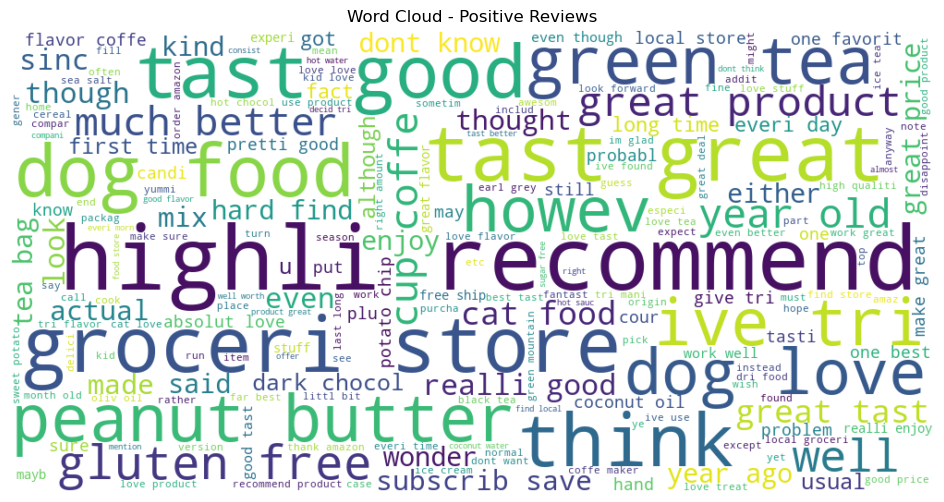

In [35]:
#Word Clouds for Positive and Negative Reviews
positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Reviews")
plt.show()

Observations:

* The word cloud highlights the most frequently occurring words in positive reviews, with larger words appearing more frequently.
    
* Words such as good, great, love, and excellent may appear prominently, indicating positive customer experiences.
    
* These frequent words help us understand the common reasons customers express satisfaction with Amazon products.

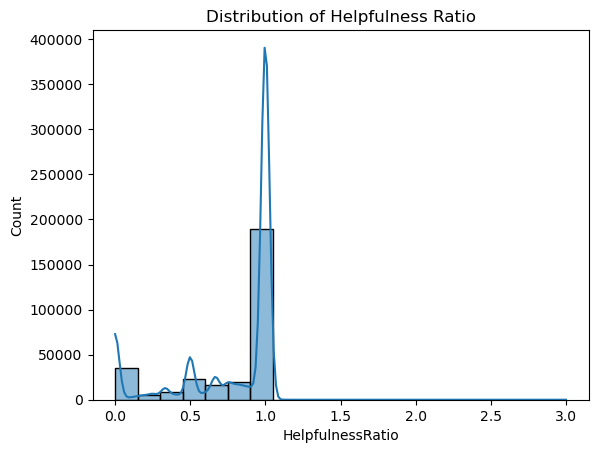

In [36]:
#Distribution of helpfulness ratio
df["HelpfulnessRatio"] = np.where(
    df["HelpfulnessDenominator"] > 0,
    df["HelpfulnessNumerator"]
    / df["HelpfulnessDenominator"],
    np.nan
)

sns.histplot(
    data=df,
    x="HelpfulnessRatio",
    bins=20,
    kde=True
)
plt.title("Distribution of Helpfulness Ratio")
plt.show()

Observations:

* The histogram shows the distribution of helpfulness ratios, indicating how helpful customers found the reviews.
    
* The helpfulness ratio ranges from 0 to 1, where a higher value indicates that a larger proportion of users who voted found the review helpful.
    
* The distribution helps us understand how helpfulness ratings vary across reviews and whether most reviews have low or high helpfulness ratios.

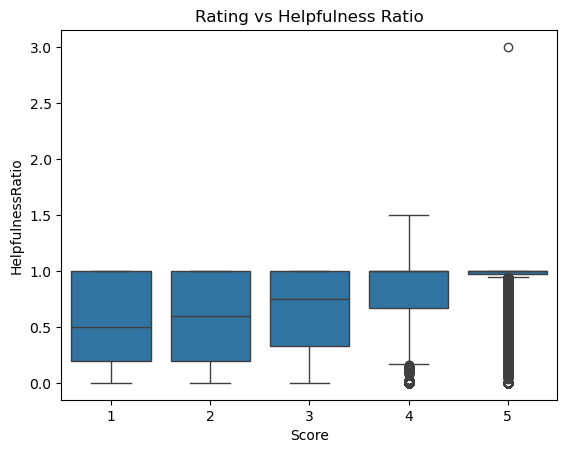

In [37]:
#Relationship between rating and helpfulness
sns.boxplot(
    data=df,
    x="Score",
    y="HelpfulnessRatio"
)
plt.title("Rating vs Helpfulness Ratio")
plt.show()

Observations:

* The box plot shows the distribution of helpfulness ratios for each rating (1 to 5).
    
* It helps compare the median helpfulness ratio and the variability of helpfulness across different ratings.
    
* This visualization helps us understand whether reviews with certain ratings tend to receive higher helpfulness ratios than reviews with other ratings.

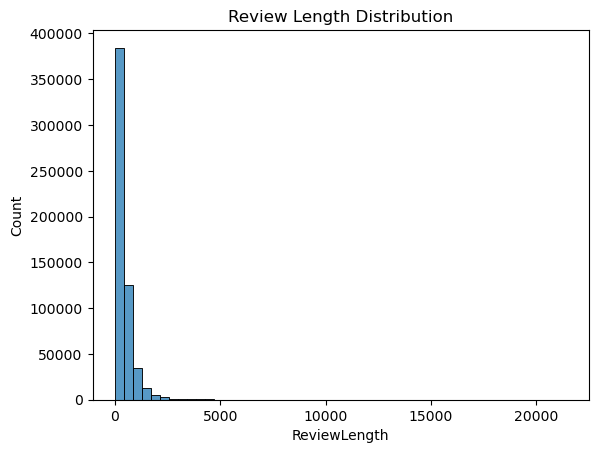

In [38]:
#Review length distribution
df["ReviewLength"] = df["Text"].str.len()

sns.histplot(data=df, x="ReviewLength", bins=50)
plt.title("Review Length Distribution")
plt.show()

Observations:

* The histogram shows the distribution of review lengths based on the number of characters in each review.
    
* It helps identify whether most reviews are short, medium, or long and shows the variation in review length.
    
* The distribution helps detect unusually long reviews and understand the text characteristics of the dataset before preprocessing and sentiment analysis.

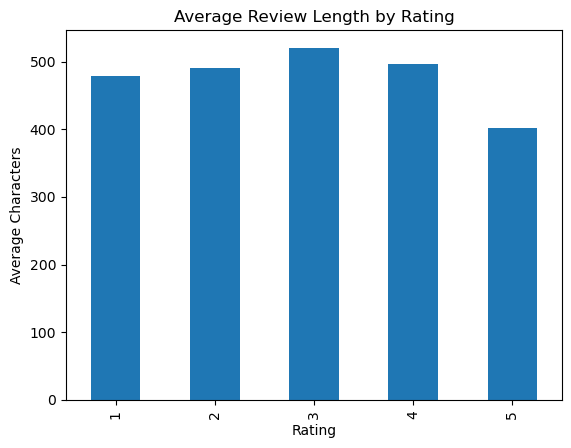

In [39]:
#Average review length by rating
avg_length = df.groupby("Score")[
    "ReviewLength"
].mean()

avg_length.plot(kind="bar")
plt.title("Average Review Length by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Characters")
plt.show()

Observations:

* The bar chart shows the average review length, measured in characters, for each rating from 1 to 5.
    
* It helps identify which rating category has the longest and shortest average reviews.
    
* Comparing average review lengths across ratings helps us understand whether customers tend to write longer or shorter reviews depending on their ratings.

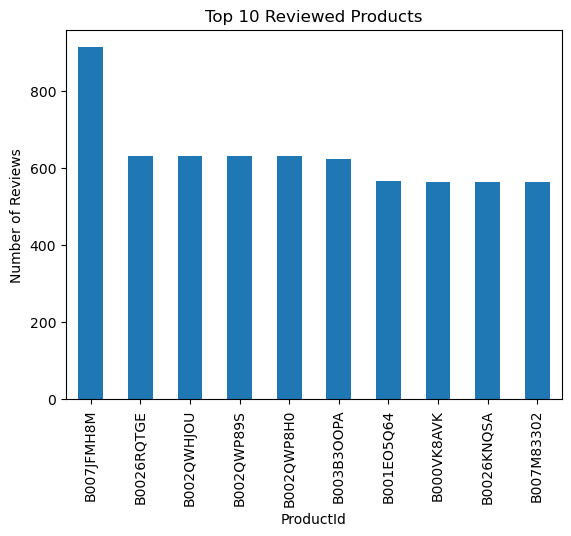

In [40]:
#Top reviewed products
top_products = df["ProductId"].value_counts().head(10)

top_products.plot(kind="bar")
plt.title("Top 10 Reviewed Products")
plt.ylabel("Number of Reviews")
plt.show()

Observations:

* The bar chart displays the top 10 products with the highest number of customer reviews in the dataset.
    
* Products with taller bars have received more reviews, indicating greater review activity from customers.

* This analysis helps identify frequently reviewed products and understand which products attract more customer feedback.

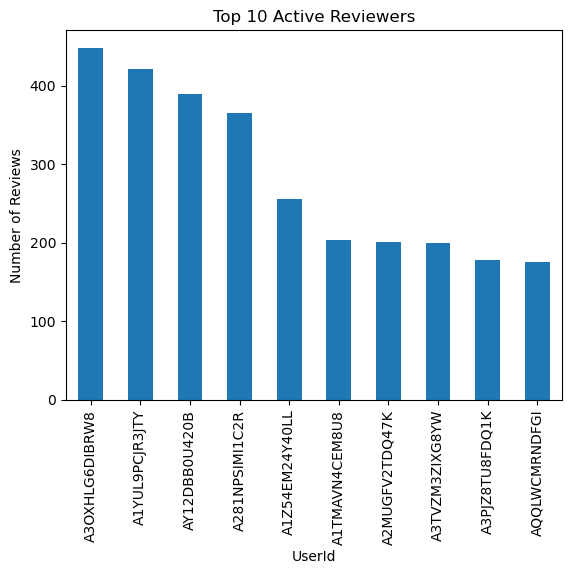

In [41]:
#Top active users
top_users = df["UserId"].value_counts().head(10)

top_users.plot(kind="bar")
plt.title("Top 10 Active Reviewers")
plt.ylabel("Number of Reviews")
plt.show()

Observations:

* The bar chart shows the top 10 users who have submitted the highest number of reviews in the dataset.
    
* Users with taller bars have written more reviews, indicating higher reviewing activity on Amazon products.
    
* This analysis helps identify the most active reviewers and understand how review contributions vary among users.

In [42]:
#Most common review words
all_words = Counter(
    " ".join(df["Cleaned_Review"]).split()
)

print(all_words.most_common(30))

[('not', 331914), ('like', 285028), ('tast', 260163), ('flavor', 217074), ('good', 202805), ('one', 191024), ('love', 187143), ('product', 181847), ('use', 175235), ('coffe', 173296), ('tri', 167898), ('great', 165277), ('tea', 151681), ('food', 151013), ('get', 140285), ('make', 124953), ('would', 123481), ('dog', 106774), ('buy', 106123), ('eat', 106025), ('time', 101864), ('realli', 100797), ('dont', 95659), ('much', 92672), ('order', 90898), ('bag', 87588), ('also', 86421), ('price', 86233), ('amazon', 83977), ('littl', 83389)]


Observations:

* The analysis identifies the 30 most frequently occurring words in the cleaned review text.
    
* These frequent words help us understand the common topics and terms customers use when describing their experiences with Amazon products.
    
* The most common words can provide useful insights into customer opinions and help identify patterns for sentiment analysis.

#### Sprint 2 – Machine Learning Model Development

In [43]:
#Define the input and target
X = df["Cleaned_Review"]
y = df["Score"]

In [44]:
#Split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

##### Feature Engineering

Experiment with different text vectorization techniques such as:

●	Bag of Words (CountVectorizer): Counts how often words occur in each review.

“good product good”

good = 2, product = 1

●	TF-IDF Vectorizer: 
Assigns weights based on how informative a word is across the collection of reviews.

Common words may receive lower weights; more distinctive words may receive higher weights.

In [45]:
#Convert text into numerical features
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(max_features=20000)

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=20000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

##### Train and Compare Multiple Models

Train and evaluate the following algorithms:
    
●	Naive Bayes: Predicts classes using probabilities

●	Logistic Regression: Learns relationships between features and classes

●	Support Vector Machine (SVM): Finds decision boundaries between classes

●	Decision Tree: Makes predictions using a series of decision rules

●	Random Forest: Combines predictions from multiple decision trees

●	K-Nearest Neighbors (KNN):Predicts based on nearby examples


In [50]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Step 1: Use a smaller subset to reduce training time
train_limit = min(20000, X_train_tfidf.shape[0])
test_limit = min(5000, X_test_tfidf.shape[0])

Xtr = X_train_tfidf[:train_limit]
Xte = X_test_tfidf[:test_limit]

ytr = y_train.iloc[:train_limit] if hasattr(y_train, "iloc") else y_train[:train_limit]
yte = y_test.iloc[:test_limit] if hasattr(y_test, "iloc") else y_test[:test_limit]

# Step 2: Define the models
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=300
    ),

    "SVM": LinearSVC(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    )
}

# Step 3: Train and evaluate each model
results = []

for name, model in models.items():

    print(f"\nTraining {name}...")
    start_time = time.time()

    model.fit(Xtr, ytr)
    y_pred = model.predict(Xte)

    elapsed_time = round(time.time() - start_time, 2)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(yte, y_pred),
        "Precision": precision_score(
            yte, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            yte, y_pred,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            yte, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Time (seconds)": elapsed_time
    })

    print(f"{name} completed in {elapsed_time} seconds.")

# Step 4: Display comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\nModel Comparison Results:")
display(results_df.round(4))



Training Naive Bayes...
Naive Bayes completed in 0.11 seconds.

Training Logistic Regression...
Logistic Regression completed in 3.46 seconds.

Training SVM...
SVM completed in 1.9 seconds.

Training Decision Tree...
Decision Tree completed in 20.09 seconds.

Training Random Forest...
Random Forest completed in 14.79 seconds.

Training KNN...
KNN completed in 4.64 seconds.

Model Comparison Results:


,Model,Accuracy,Precision,Recall,F1 Score,Time (seconds)
0,SVM,0.6990,0.6500,0.6990,0.6644,1.90
1,Logistic Regression,0.6998,0.6402,0.6998,0.6435,3.46
2,Random Forest,0.6778,0.7617,0.6778,0.5785,14.79
3,Decision Tree,0.5826,0.5719,0.5826,0.5769,20.09
4,KNN,0.6078,0.5402,0.6078,0.5639,4.64
5,Naive Bayes,0.6404,0.4967,0.6404,0.5004,0.11


##### Evaluation Metrics

Evaluate the models using:
    
●	Accuracy: Percentage of all predictions that are correct.
    
●	Precision: Of the predictions for a class,how many were correct?

●	Recall: Of the actual examples in a class,how many did the model identify correctly?

●	F1-Score: Combines precision and recall.
    
●	Confusion Matrix: Shows actual ratings against predicted ratings.
    
●	Classification Report: Displays precision,recall,F1-Score, and support for each rating.


              precision    recall  f1-score   support

           1       0.63      0.50      0.56     10454
           2       0.38      0.07      0.12      5954
           3       0.40      0.16      0.23      8528
           4       0.42      0.18      0.25     16131
           5       0.74      0.96      0.84     72624

    accuracy                           0.70    113691
   macro avg       0.52      0.38      0.40    113691
weighted avg       0.64      0.70      0.65    113691



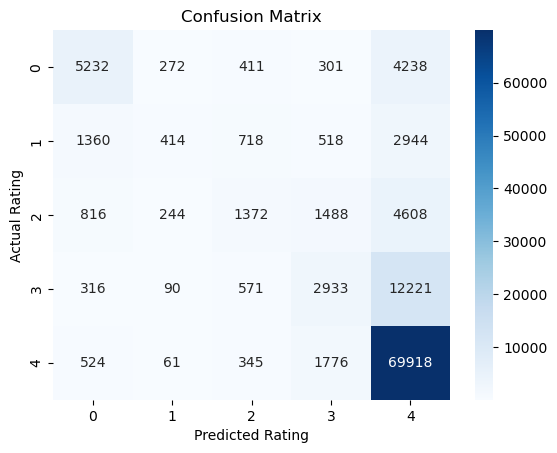

In [51]:
#Understand the evaluation metrics
best_model = models["Logistic Regression"]  # Example only
y_pred = best_model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.title("Confusion Matrix")
plt.show()

Observations:

* The SVM model achieved 70% accuracy overall, indicating that approximately 70% of the predictions were correct on the evaluated test dataset.
  
* The model performs best for Rating 5, with a precision of 0.74 and a recall of 0.96, achieving an F1-score of 0.84. This indicates that the model identifies most of the actual 5-star reviews correctly.

* The model performs poorly for Rating 2, with a recall of only 0.07 and an F1-score of 0.12. It also struggles to identify Ratings 3 and 4, indicating that the model has difficulty distinguishing between the middle rating categories.

  
* The weighted average F1-score is 0.65, while the macro average F1-score is 0.40. This difference suggests that the model performs unevenly across rating categories, partly because Rating 5 has many more samples than the other classes.

  
* Overall, the model predicts 5-star reviews effectively but needs improvement in identifying Ratings 2, 3, and 4. Class imbalance handling and hyperparameter tuning may help improve performance across all rating categories.

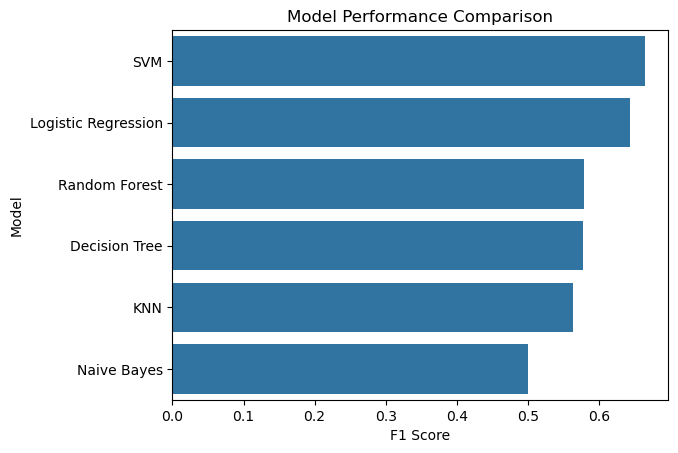

In [52]:
#Compare the models
results_df = results_df.sort_values(
    "F1 Score", ascending=False
)

sns.barplot(data=results_df, x="F1 Score", y="Model")
plt.title("Model Performance Comparison")
plt.show()

Observations:

* The bar chart compares the weighted F1-scores of six machine learning models to identify their performance in predicting Amazon review ratings.
  
* SVM achieved the highest F1-score (0.6644), followed by Logistic Regression (0.6435), making SVM the best-performing candidate based on the F1-score.

* Naive Bayes achieved an F1-score of 0.5004, while Decision Tree and KNN showed lower performance than SVM and Logistic Regression.

* Overall, SVM provides the best balance of precision and recall among the evaluated models. However, its performance on individual rating categories should also be considered before final selection.